In [1]:
#IMPORT LIBS
import geopandas as gpd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import Point
import cartopy.util as cutil
import statsmodels.api as sm
from tqdm import tqdm
from scipy import stats

#my own classes
import sys
sys.path.append("/Users/michelefilippucci/Prog/github/blocktrack/lib")
import blocktoolbox as BT
sys.path.append("/Users/michelefilippucci/Prog/github/AtmBlockPy/lib")
import BlockPlots as BP

### MASK 1
A mask with the shape of greenland

In [2]:
if True:

    # Load the world shapefile from GeoPandas datasets
    world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
    
    # Filter the dataset to only include Greenland
    greenland = world[world['name'] == 'Greenland'].explode(index_parts=False)
    
    # Define the resolution and create a grid of latitudes and longitudes
    lat_resolution = 2.5  # Resolution of 2.5 degrees
    lon_resolution = 2.5  # Resolution of 2.5 degrees
    
    # Define latitude and longitude ranges (rough bounds around Greenland)
    latitudes = np.arange(0, 91, lat_resolution)
    longitudes = np.arange(-180, +180, lon_resolution)
    
    # Initialize a mask with zeros
    mask = np.zeros((len(latitudes), len(longitudes)))
    
    # Create the mask: 1 inside Greenland, 0 outside
    for i, lat in enumerate(latitudes):
        for j, lon in enumerate(longitudes):
            point = Point(lon, lat)
            if any(greenland.contains(point)):
                mask[i, j] = 1
    
    # Convert the mask to an xarray DataArray
    mask_xr = xr.DataArray(mask, coords=[latitudes, longitudes], dims=["lat", "lon"])
    mask_bool = mask_xr.data == 1

### MASK 2
A mask with rectangular shape

In [3]:
if False:

    # Define the resolution
    lat_resolution = 2.5  # 2.5 degrees
    lon_resolution = 2.5  # 2.5 degrees
    
    # Define the global latitude and longitude ranges
    latitudes = np.arange(0, 91, lat_resolution)  # From 0°N to 90°N
    longitudes = np.arange(-180, 180, lon_resolution)  # From -180°E to 180°E
    
    # Initialize a global mask with zeros
    mask = np.zeros((len(latitudes), len(longitudes)))
    
    # Define the rectangular bounding box around Greenland (60°–80°N, 20°–80°W)
    lat_min, lat_max = 60, 80
    lon_min, lon_max = -80, -20
    
    # Assign 1 to grid points within the bounding box
    for i, lat in enumerate(latitudes):
        if lat_min <= lat <= lat_max:
            for j, lon in enumerate(longitudes):
                if lon_min <= lon <= lon_max:
                    mask[i, j] = 1
    
    # Convert the mask to an xarray DataArray
    mask_xr = xr.DataArray(mask, coords=[latitudes, longitudes], dims=["lat", "lon"])
    mask_bool = mask_xr.data == 1

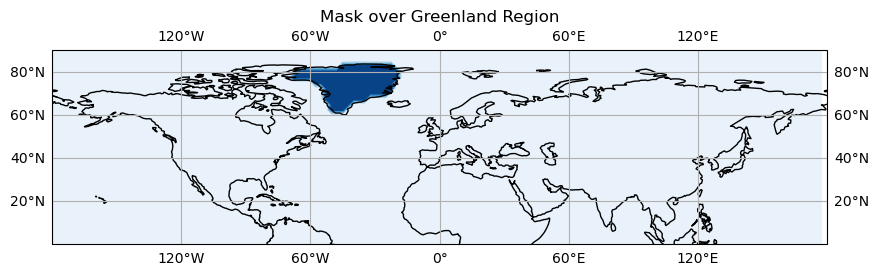

In [4]:
#LET's MAKE A PLOT TO VISUALIZE THE DOMAIN
# Plot the mask using Cartopy
plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-180, 180, 0, 90], crs=ccrs.PlateCarree())

# Plot the mask data
plt.contourf(mask_xr['lon'], mask_xr['lat'], mask_xr, cmap='Blues', transform=ccrs.PlateCarree())

# Add coastlines and gridlines
ax.add_feature(cfeature.COASTLINE)
ax.gridlines(draw_labels=True)

# Add title
plt.title('Mask over Greenland Region')

# Show the plot
plt.show()

In [5]:
%cd /Users/michelefilippucci/Data/ERA5/gr_tracking
!ls

/Users/michelefilippucci/Data/ERA5/gr_tracking
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1990.nc
dictionaries


In [6]:
ds_filt = xr.open_dataset('ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc')
GHA_filt = ds_filt['GHA_tracked']
times = ds_filt['time']
lons = ds_filt['lon']
lats = ds_filt['lat']

In [7]:
#Greenland coordinates
plon,plat=-35.0,70.0 #Greenland

In [8]:
months = ['06','07','08']

In [9]:
GHA_bool = GHA_filt.values
ds = ds_filt
dic_for_filtering = np.load('dictionaries/ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023_DIC.npy',allow_pickle=True) #original
#create a list of indexes
indexes = []
timings = []
for t in tqdm(range(len(ds["time"].values))):
    for l in np.unique(GHA_bool[t,:,:])[1:]:
        month = str(dic_for_filtering[l]['date'])[5:7]
        if l!=0 and l not in indexes and np.any(GHA_bool[t,mask_bool]==l) and month in months:
            indexes.append(l)
            timings.append(t)
print(len(indexes))        

100%|██████████████████████████████████████████████████████████████| 30681/30681 [00:01<00:00, 19010.26it/s]

237


In [10]:
print(len(dic_for_filtering))

2712


In [11]:
print(np.amax(GHA_bool))

2711


In [12]:
"""
A list of trajectories is then produced
"""
dic = []
for i,l in tqdm(enumerate(indexes)):
    dic.append({})
    dic[i]['track'] = dic_for_filtering[l]['track']
    dic[i]['area'] = dic_for_filtering[l]['avg_area']
    dic[i]['date'] = dic_for_filtering[l]['date']
    dic[i]['avg_dist_traveled'] = dic_for_filtering[l]['avg_dist_traveled']

237it [00:00, 684607.47it/s]


/Users/michelefilippucci/miniconda3/envs/blocktoolbox_env/lib/python3.8/site-packages/cartopy/mpl/gridliner.py:451: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/Users/michelefilippucci/miniconda3/envs/blocktoolbox_env/lib/python3.8/site-packages/cartopy/mpl/gridliner.py:475: UserWarning: The .ylabels_left attribute is deprecated. Please use .left_labels to toggle visibility instead.
  warnings.warn('The .ylabels_left attribute is deprecated. Please '


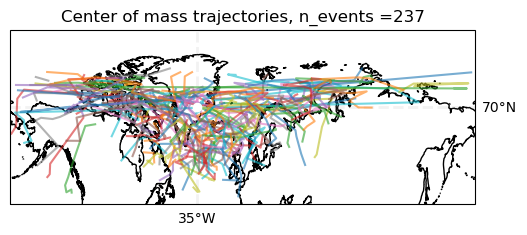

In [13]:
'''
TRAJECTORY PLOT
'''

import matplotlib.ticker as mticker

plt.figure(figsize=(6,6))

#dic =np.load("/Users/michelefilippucci/Prog/summer_greenland_block/data_tmp/dic_"+str(plon)+"-"+str(plat)+".npy",allow_pickle=True)
xs=[]
ys=[]
areas = []
for i in range(len(indexes)):
    #if 1959 == int(str(ds["time"].values[timings[i]])[0:4]):
    xs.append(dic[i]['track'][0])
    ys.append(dic[i]['track'][1])
    areas.append(dic[i]['area'])
output = "/home/mich/plots/POSTER/snapshots/trajectories_"+str(plon)+"-"+str(plat)+".png"
#plot the trajectories to see what you are looking at
mapcrs = ccrs.PlateCarree()
datacrs = ccrs.PlateCarree()
extent =[-180,+180,45,90]
ax = plt.subplot(111, projection=mapcrs)
ax.set_extent(extent, datacrs)
ax.coastlines()
ax.set_aspect(3)
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=2, color='gray', alpha=0.1, linestyle='--')
gl.xlocator = mticker.FixedLocator([plon])
gl.ylocator = mticker.FixedLocator([plat])
gl.xlabels_top = False
gl.ylabels_left = False
for i in range(len(xs)):
    #print(len(xs[i]))
    cm = plt.plot(ys[i],xs[i],alpha=0.6,transform=datacrs)
#plt.text(30,60, 'n_events='+str(len(xs)), fontsize = 9)
plt.plot(plon,plat,'ow',transform=datacrs)#transorm=datacrs)
plt.title('Center of mass trajectories, n_events =' + str(len(xs)), loc = 'center')


#plt.show()
#plt.savefig(output,bbox_inches='tight',dpi=400)
plt.savefig('/Users/michelefilippucci/PLOTS/EGU/trajectories.png',dpi=300)



In [14]:
print(ys[32])

[-32.5, -36.897590361445765, -37.43333333333334, -38.58974358974359]


In [15]:
dff = ys.copy()

In [16]:
count = 0
for i,y in enumerate(ys):
    dff[i] = np.diff(y)
    if np.any(abs(dff[i])>180):
        count += 1
        print(dff[i],indexes[i],i)
print(count)

[  5.68  -5.47  -0.42  -6.96 312.66 -22.23  -3.65 -35.75 -34.63  -2.09
  -0.73] 863 79
[  2.07 300.01  -9.56] 1912 162
[-348.82    5.89    9.18   22.75] 2035 170
3


In [17]:
xs=[]
ys=[]
areas = []
for i in range(len(indexes)):
    xs.append(dic[i]['track'][1])
    ys.append(dic[i]['track'][0])
    areas.append(dic[i]['area'])
#we want to store:
#-event label: dictionary key*
#-month
#-year
#-avg area in lifetime
#-initial distance from point
#-final distance from point 
#-duration
feature_dictionaries = []
for i,l in tqdm(enumerate(indexes)):
    event = {"label":l,
            "month":str(ds["time"].values[timings[i]])[5:7],
            "year":str(ds["time"].values[timings[i]])[0:4],
            "avg_area":np.mean(areas[i]),
            "duration":len(xs[i]),
            "initial_distance":((plon-xs[i][0])**2+(plat-ys[i][0])**2)**0.5,
            "final_distance":((plon-xs[i][-1])**2+(plat-ys[i][-1])**2)**0.5,
            "displacement_lon":plon-xs[i][0],
            "displacement_lat":plat-ys[i][0]
            }
    feature_dictionaries.append(event)

237it [00:00, 27512.39it/s]


In [18]:
def feature_list(feature_dictionaries,quantity,bin_size_y=10,year_range=(1943,2024)):
    y_array = np.arange(year_range[0]+bin_size_y/2,year_range[1]-bin_size_y/2,1)
    arr = np.zeros(len(y_array))
    arr_err = np.zeros(len(y_array))
    list_err = []
    for j,y in enumerate(y_array):
        count = 0
        for item in feature_dictionaries:
            if int(item["year"]) >= y-bin_size_y/2 and int(item["year"]) < y + bin_size_y/2:
                count += 1
                try:
                    arr[j] += item[quantity]
                    list_err.append(item[quantity])
                except:
                    arr[j] += 1 #the number of events case
        if quantity != "number_of_events":
            arr[j] = arr[j]/count
    if quantity != "number_of_events":
        for j,y in enumerate(y_array):
            arr_err[j] = np.std(list_err)
    if quantity == "number_of_events":
        for j,y in enumerate(y_array):
            arr_err[j]=np.std(arr[:])
    return y_array,arr,arr_err

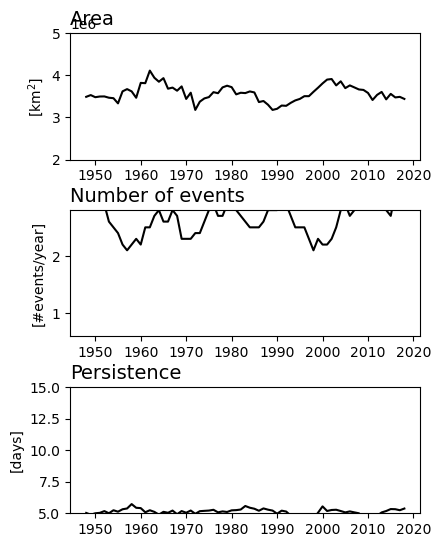

In [19]:
y,area,area_err = feature_list(feature_dictionaries,'avg_area')
y,n_ev,n_ev_err = feature_list(feature_dictionaries,'number_of_events')
y,duration,duration_err = feature_list(feature_dictionaries,'duration')

plt.rcParams['figure.figsize'] = [5,6]

fig, axes = plt.subplots(nrows=3,ncols=1)
axes.flatten()
axes[0].plot(y,area,color='black',label='area')
axes[0].set_title('Area',loc='left',fontsize=14)
axes[0].set_ylabel('[km$^2$]')
axes[0].set_ylim((2e6,5e6))
axes[1].plot(y,n_ev/10,color='black',label='number_of_events')
axes[1].set_title('Number of events',loc='left',fontsize=14)
axes[1].set_ylabel('[#events/year]')
axes[1].set_ylim((0.6,2.8))
axes[2].plot(y,duration,color='black',label='persistence')
axes[2].set_title('Persistence',loc='left',fontsize=14)
axes[2].set_ylabel('[days]')
axes[2].set_ylim((5,15))

plt.subplots_adjust(left=0.2,
                    bottom=0.1, 
                    right=0.9, 
                    top=0.9, 
                    wspace=0.4, 
                    hspace=0.4)


plt.savefig('/Users/michelefilippucci/PLOTS/EGU/characteristics.png',dpi=300)

In [20]:
# LET'S TRY TO SELECT EVENTS COMING FROM THE WEST AND EAST
feature_dictionaries_east = []
feature_dictionaries_west = []
for i,l in tqdm(enumerate(indexes)):
    displacement_lon = plon-xs[i][0]
    if displacement_lon < 0:
        event = {"label":l,
                "month":str(ds["time"].values[timings[i]])[5:7],
                "year":str(ds["time"].values[timings[i]])[0:4],
                "avg_area":np.mean(areas[i]),
                "duration":len(xs[i]),
                "initial_distance":((plon-xs[i][0])**2+(plat-ys[i][0])**2)**0.5,
                "final_distance":((plon-xs[i][-1])**2+(plat-ys[i][-1])**2)**0.5,
                "displacement_lon":plon-xs[i][0],
                "displacement_lat":plat-ys[i][0]
                }
        feature_dictionaries_east.append(event)
    if displacement_lon >= 0:
        event = {"label":l,
                "month":str(ds["time"].values[timings[i]])[5:7],
                "year":str(ds["time"].values[timings[i]])[0:4],
                "avg_area":np.mean(areas[i]),
                "duration":len(xs[i]),
                "initial_distance":((plon-xs[i][0])**2+(plat-ys[i][0])**2)**0.5,
                "final_distance":((plon-xs[i][-1])**2+(plat-ys[i][-1])**2)**0.5,
                "displacement_lon":plon-xs[i][0],
                "displacement_lat":plat-ys[i][0]
                }
        feature_dictionaries_west.append(event)

237it [00:00, 3794.79it/s]


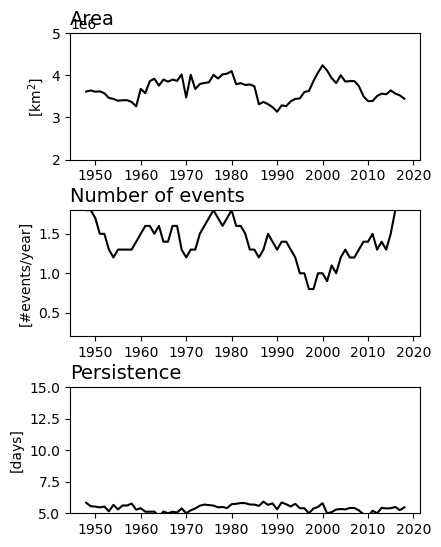

In [21]:
#EAST

y,area,area_err = feature_list(feature_dictionaries_east,'avg_area')
y,n_ev,n_ev_err = feature_list(feature_dictionaries_east,'number_of_events')
y,duration,duration_err = feature_list(feature_dictionaries_east,'duration')
# Fit linear regression model with errors

fig, axes = plt.subplots(nrows=3,ncols=1)
axes.flatten()
axes[0].plot(y,area,color='black',label='area')
axes[0].set_title('Area',loc='left',fontsize=14)
axes[0].set_ylabel('[km$^2$]')
axes[0].set_ylim((2e6,5e6))
axes[1].plot(y,n_ev/10,color='black',label='number_of_events')
axes[1].set_title('Number of events',loc='left',fontsize=14)
axes[1].set_ylabel('[#events/year]')
axes[1].set_ylim((0.2,1.8))
axes[2].plot(y,duration,color='black',label='persistence')
axes[2].set_title('Persistence',loc='left',fontsize=14)
axes[2].set_ylabel('[days]')
axes[2].set_ylim((5,15))

plt.subplots_adjust(left=0.2,
                    bottom=0.1, 
                    right=0.9, 
                    top=0.9, 
                    wspace=0.4, 
                    hspace=0.4)

plt.savefig('/Users/michelefilippucci/PLOTS/EGU/characteristics_from_east.png',dpi=300)


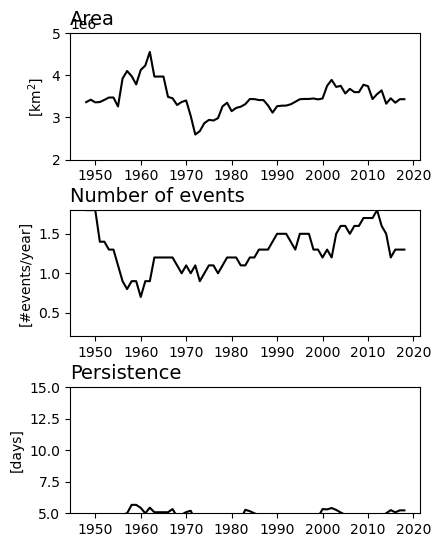

In [22]:
#WEST

y,area,area_err = feature_list(feature_dictionaries_west,'avg_area')
y,n_ev,n_ev_err = feature_list(feature_dictionaries_west,'number_of_events')
y,duration,duration_err = feature_list(feature_dictionaries_west,'duration')

fig, axes = plt.subplots(nrows=3,ncols=1)
axes.flatten()
axes[0].plot(y,area,color='black',label='area')
axes[0].set_title('Area',loc='left',fontsize=14)
axes[0].set_ylabel('[km$^2$]')
axes[0].set_ylim((2e6,5e6))
axes[1].plot(y,n_ev/10,color='black',label='number_of_events')
axes[1].set_title('Number of events',loc='left',fontsize=14)
axes[1].set_ylabel('[#events/year]')
axes[1].set_ylim((0.2,1.8))
axes[2].plot(y,duration,color='black',label='persistence')
axes[2].set_title('Persistence',loc='left',fontsize=14)
axes[2].set_ylabel('[days]')
axes[2].set_ylim((5,15))

plt.subplots_adjust(left=0.2,
                    bottom=0.1, 
                    right=0.9, 
                    top=0.9, 
                    wspace=0.4, 
                    hspace=0.4)

plt.savefig('/Users/michelefilippucci/PLOTS/EGU/characteristics_from_west.png',dpi=300)

In [23]:
#COMPOSITES EAST WEST

In [24]:
labels_est = []
for event in feature_dictionaries_east:
    labels_est.append(event['label'])
labels_west = []
for event in feature_dictionaries_west:
    labels_west.append(event['label'])

In [25]:
print(labels_est)
print(labels_west)

[11, 67, 71, 99, 103, 145, 149, 172, 173, 174, 211, 240, 246, 249, 250, 283, 285, 314, 318, 359, 427, 450, 452, 494, 516, 547, 585, 591, 618, 647, 648, 651, 684, 737, 762, 763, 764, 797, 798, 829, 835, 865, 899, 938, 941, 976, 1013, 1044, 1051, 1083, 1138, 1171, 1176, 1177, 1202, 1236, 1238, 1239, 1263, 1266, 1271, 1302, 1308, 1342, 1345, 1369, 1433, 1453, 1458, 1490, 1518, 1551, 1552, 1572, 1607, 1615, 1643, 1674, 1677, 1709, 1711, 1778, 1813, 1818, 1851, 1885, 1973, 2032, 2035, 2058, 2066, 2097, 2117, 2150, 2151, 2152, 2208, 2212, 2248, 2346, 2347, 2348, 2376, 2382, 2384, 2411, 2444, 2447, 2478, 2503, 2542, 2562, 2567, 2570, 2598, 2602, 2603, 2630, 2632, 2657, 2662, 2704]
[9, 10, 15, 17, 46, 68, 76, 106, 139, 141, 147, 176, 178, 180, 182, 215, 242, 320, 321, 354, 356, 360, 383, 384, 421, 453, 486, 489, 492, 548, 685, 703, 739, 743, 771, 800, 827, 833, 863, 897, 901, 902, 1008, 1054, 1089, 1139, 1143, 1166, 1203, 1209, 1232, 1264, 1310, 1343, 1402, 1411, 1434, 1454, 1463, 1485, 1520, 